# Exploratory Data analysis
I want to train a decision tree (DT), so I would like to know:

1. Which features have missing values
1. Which features are categorical or continuous
1. Which features have very strong correlations such that one should be removed
1. Which features have skew class distributions, since DTs are not robust to
   skew classes


In [44]:
import pandas as pd
import numpy as np

df = pd.read_csv("~/Laboratory/datasets/unsw_nb15/networkTraffic.csv")
df = df.replace('?', np.nan) # to make them the same type

### Missing Values

In [45]:
# Find the missing columns
missing_cols = df.columns[df.isnull().any()]

# print missing percentage
for missing_col in missing_cols:
    print(f'{missing_col}: {df[missing_col].isnull().mean() * 100:.2f}% missing')

service: 54.85% missing


In [46]:
df['service'].unique()

<StringArray>
[       nan,     'http',      'ftp', 'ftp-data',     'smtp',     'pop3',
      'dns',     'snmp',      'ssl',     'dhcp',      'irc',   'radius',
      'ssh']
Length: 13, dtype: str

So `service` is missing 54.84% of its instances, and it indicates what
application-layer communication protocol was used.

To decide whether or not to keep the feature, I want to see if it indicates an
attack.

In [47]:
print(f'The target column is: {df.columns[-1]}')
print(f'Which has these values: {df[df.columns[-1]].unique()}')

The target column is: attack_cat
Which has these values: [0 1 2 3 4 5 6 7 8 9]


Records with `attac_cat == 0` are normal packets, the other are different
attacks.

I want to see if missingness can help predict any of the attack categories.

In [48]:
# Cross-tabulate missing service against individual attack categories
print("=== Attack Categories vs Service Missingness ===")
print(pd.crosstab(
    df['service'].isna().rename('service_is_NaN'), 
    df['attack_cat'], 
    normalize='columns'  # Shows % of each attack category that has missing service
) * 100)


=== Attack Categories vs Service Missingness ===
attack_cat              0          1          2          3         4  \
service_is_NaN                                                         
False           31.304301  15.778938   4.723057  15.336635  48.24256   
True            68.695699  84.221062  95.276943  84.663365  51.75744   

attack_cat             5          6          7      8          9  
service_is_NaN                                                    
False           21.06836   9.345871  85.057471    0.0  98.445754  
True            78.93164  90.654129  14.942529  100.0   1.554246  


For attack cagegories like 2, 3, 6, and 8, there is clear signal. I'm going to
re-mark the missing values as `other`.

In [49]:
df['service'] = df['service'].fillna('other')
print("Remaining missing in service:", df['service'].isna().sum())

Remaining missing in service: 0


### Identifying Numerical and Categorical Features

The file `UNSW-NB15_features.csv` contains metadata about the features. For each
feature it stores:
 - `Name`: the feature's name
 - `Type`: the feature's data type (e.g. float vs string)
 - `Description`: a description of what the feature measures

In [77]:
meta_df = pd.read_csv("~/Laboratory/datasets/unsw_nb15/UNSW-NB15_features.csv")

# Load dataframes
print("Training data types:")
print(df.dtypes.value_counts().to_string(), end='\n\n')
print("Meta data types:")
print(meta_df['Type'].value_counts().to_string())

Training data types:
int64      30
float64    11
str         3

Meta data types:
Type
integer    27
float      11
nominal     4
binary      2


In [81]:
meta_df["Kind"] = meta_df["Type"].map({
    "nominal": "categorical",
    "binary": "categorical",
    "integer": "discrete numerical",
    "float": "continuous numerical",
})

# Exclude the target, identifier, redundant feature, and the binary
# attack label, which would leak information about attack_cat.
excluded = {"attack_cat", "id", "is_ftp_login"}

predictors = meta_df.loc[
    ~meta_df["Name"].isin(excluded)
].copy()

categorical = predictors.loc[
    predictors["Type"].isin(["nominal", "binary"]), "Name"
].tolist()

numerical = predictors.loc[
    predictors["Type"].isin(["integer", "float"]), "Name"
].tolist()

print("Categorical:", categorical)
print("Numerical:", numerical)

Categorical: ['proto', 'service', 'state', 'is_sm_ips_ports']
Numerical: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst']


In [82]:
for col in categorical:
    print(f'{col} cardinnality: {df[col].nunique()}')

proto cardinnality: 133
service cardinnality: 13
state cardinnality: 11
is_sm_ips_ports cardinnality: 2


### Removing strong correlations

In [83]:
# Use training data only for feature-selection decisions.
num_cols = [col for col in numerical if col in df.columns]

spearman = df[num_cols].corr(method="spearman")
pearson = df[num_cols].corr(method="pearson")

In [84]:
from itertools import combinations
import pandas as pd

pairs = pd.DataFrame(
    [
        {
            "feature_1": a,
            "feature_2": b,
            "spearman": spearman.loc[a, b],
            "pearson": pearson.loc[a, b],
        }
        for a, b in combinations(num_cols, 2)
    ],
    columns=["feature_1", "feature_2", "spearman", "pearson"],
)

pairs["strength"] = pairs[["spearman", "pearson"]].abs().max(axis=1)

strong_pairs = (
    pairs.loc[pairs["strength"] >= 0.95]
    .sort_values("strength", ascending=False)
)

print(strong_pairs.to_string(index=False))

     feature_1        feature_2  spearman   pearson  strength
   trans_depth ct_flw_http_mthd  0.999563  0.251975  0.999563
        dbytes            dloss  0.947647  0.996711  0.996711
        tcprtt           synack  0.996267  0.943053  0.996267
        sbytes            sloss  0.830944  0.995772  0.995772
        tcprtt           ackdat  0.992658  0.920218  0.992658
         dpkts           dbytes  0.989424  0.973445  0.989424
        synack           ackdat  0.981722  0.737615  0.981722
          swin             dwin  0.980518  0.980458  0.980518
         dpkts            dloss  0.957333  0.979612  0.979612
    ct_srv_src       ct_srv_dst  0.916672  0.979467  0.979467
         spkts            sloss  0.929290  0.971859  0.971859
         spkts           sbytes  0.897137  0.964393  0.964393
         dload            dmean  0.963142  0.547562  0.963142
    ct_dst_ltm ct_src_dport_ltm  0.773512  0.961518  0.961518
        dbytes            dmean  0.960883  0.405260  0.960883
ct_dst_s

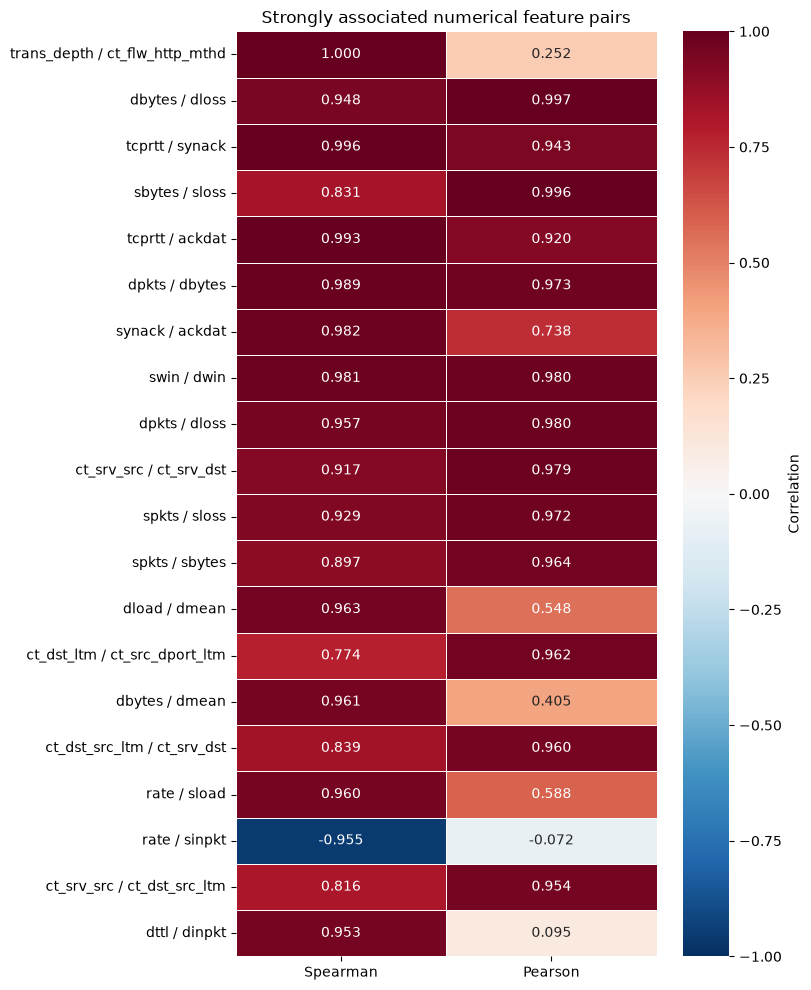

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = strong_pairs.copy()

plot_df["pair"] = (
    plot_df["feature_1"] + " / " + plot_df["feature_2"]
)

heatmap_data = (
    plot_df.set_index("pair")[["spearman", "pearson"]]
    .rename(columns={
        "spearman": "Spearman",
        "pearson": "Pearson",
    })
)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(heatmap_data) + 2))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Correlation"},
    ax=ax,
)

ax.set_title("Strongly associated numerical feature pairs")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()

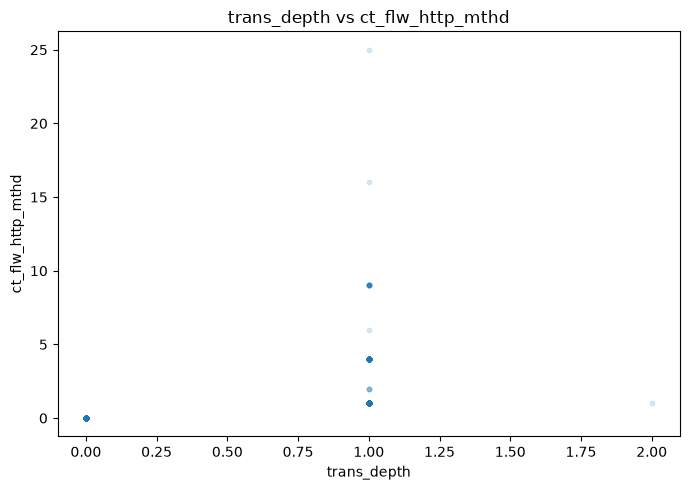

In [88]:
a, b = "trans_depth", "ct_flw_http_mthd"

# Sample for plotting only; correlations use the full training data.
sample = df[[a, b]].dropna()
sample = sample.sample(n=min(10_000, len(sample)), random_state=42)

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(sample[a], sample[b], s=10, alpha=0.15)
ax.set_xlabel(a)
ax.set_ylabel(b)
ax.set_title(f"{a} vs {b}")

plt.tight_layout()
plt.show()

### Summary of changes made to the data

1. Changed missing values to `other` in the `service` feature because
   missingness had a strong correlation to certain attacks.

I identified the following features as Categorical:
```
['proto', 'service', 'state', 'is_sm_ips_ports']
```

And the following features as Numerical:
```
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst']
```



In [89]:
df.to_csv("./data/networkTraffic.csv")